In [3]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Machine Learning
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Loading CSVs using path.cwd
PROJECT_ROOT = Path.cwd().parent
RAW_DATA = PROJECT_ROOT / "FIFA WC Dataset"
ML_DATA = PROJECT_ROOT / "ml_data"
ML_DATA.mkdir(exist_ok=True)
train = pd.read_csv(ML_DATA / "train.csv")
test = pd.read_csv(ML_DATA / "test.csv")


In [4]:
print(f" Training set shape: {train.shape}")
print(f" Testing set shape: {test.shape}")

 Training set shape: (21257, 108)
 Testing set shape: (2503, 108)


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 21257 entries, 0 to 21256
Columns: 108 entries, home_elo to target
dtypes: float64(106), int64(2)
memory usage: 17.5 MB


In [6]:
train.isnull().sum().sum()

np.int64(0)

In [7]:
train["target"].value_counts(normalize=True) * 100

target
2    48.224114
0    28.127205
1    23.648680
Name: proportion, dtype: float64

In [8]:
# Separate features and target
X_train = train.drop(columns="target")
y_train = train["target"]

X_test = test.drop(columns="target")
y_test = test["target"]

In [9]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (21257, 107)
y_train: (21257,)
X_test : (2503, 107)
y_test : (2503,)


In [10]:
# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=4
)

In [11]:
# applying the model and training it on X_train and y_train

rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

In [12]:
y_pred = rf_model.predict(X_test)

In [13]:
# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 0.5989
Accuracy: 59.89%


In [14]:
# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 455   34  229]
 [ 195   42  366]
 [ 145   35 1002]]


In [15]:
# Print classification report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.57      0.63      0.60       718
           1       0.38      0.07      0.12       603
           2       0.63      0.85      0.72      1182

    accuracy                           0.60      2503
   macro avg       0.53      0.52      0.48      2503
weighted avg       0.55      0.60      0.54      2503



In [16]:
# There is a problem with Draw results. The model is doing something like: 
# "If Team A looks stronger, predict a home win. 
# If Team B looks stronger, predict an away win. 
# Otherwise lean toward a win rather than a draw."

In [17]:
# Predictions on the training set
y_train_pred = rf_model.predict(X_train)

# Training accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Training Accuracy: {train_accuracy * 100:.2f}%")

Training Accuracy: 0.9993
Training Accuracy: 99.93%


In [18]:
# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
feature_importance.head(20)

,Feature,Importance
2,elo_diff,0.106678
1,away_elo,0.073968
0,home_elo,0.073470
8,away_avg_ga,0.073184
7,home_avg_ga,0.071112
4,away_win_pct,0.067819
6,away_avg_gf,0.066150
3,home_win_pct,0.064814
5,home_avg_gf,0.064743
14,home_last5_avg_ga,0.045835


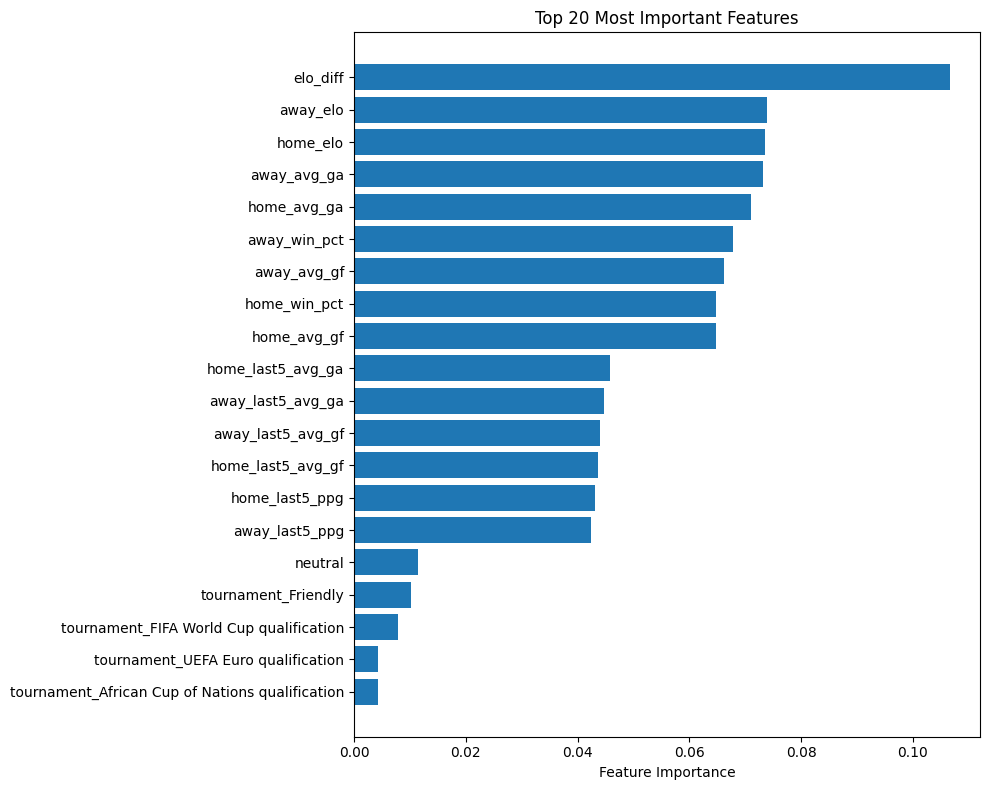

In [19]:
# Plot top 20 features
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance["Feature"][:20][::-1],
    feature_importance["Importance"][:20][::-1]
)

plt.xlabel("Feature Importance")
plt.title("Top 20 Most Important Features")
plt.tight_layout()

plt.show()

# Random Forest V1 (Baseline)

- I Built the first baseline Random Forest using default hyperparameters.
- Established the evaluation pipeline (accuracy, confusion matrix, classification report).
- the model Achieved good overall accuracy but showed severe overfitting (99.92% train vs 60.12% test).
- This will served as the reference model for all future Random Forest experiments.